# Hierarchical Clustering on Iris Dataset

We will:
1. Load the real dataset
2. Look at the data
3. Create a dendrogram
4. Draw a cut to identify the number of clusters
5. Apply Agglomerative Clustering
6. Visualize the clusters

**Main idea:** The dendrogram helps us decide how many clusters to use.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram


## 1. Load the Iris dataset

In [ ]:
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)

print("Shape:", df.shape)
df.head()


Shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Iris has **150 samples and 4 features**:

- Sepal length
- Sepal width
- Petal length
- Petal width

The species labels are available in the dataset, but we will **not use them for clustering** because clustering is unsupervised.

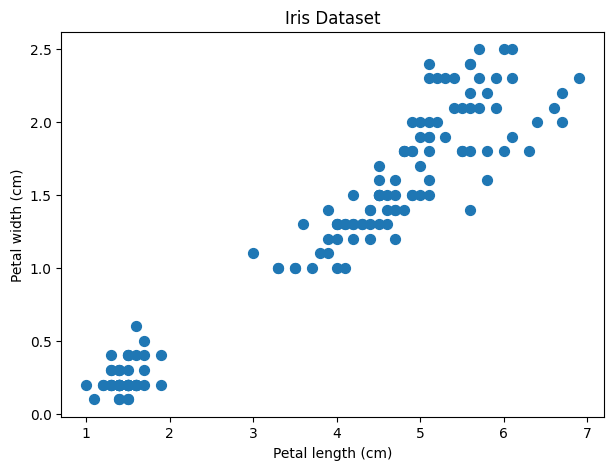

In [ ]:
# Visualize two features of the real dataset
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 2],
    X[:, 3],
    s=50
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Dataset")
plt.show()


## 2. Standardize the features

Hierarchical clustering uses distances. Standardization puts the four features on a comparable scale.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## 3. Create the dendrogram

Here we use **Ward linkage**.

The dendrogram shows how individual observations are progressively merged into larger clusters.

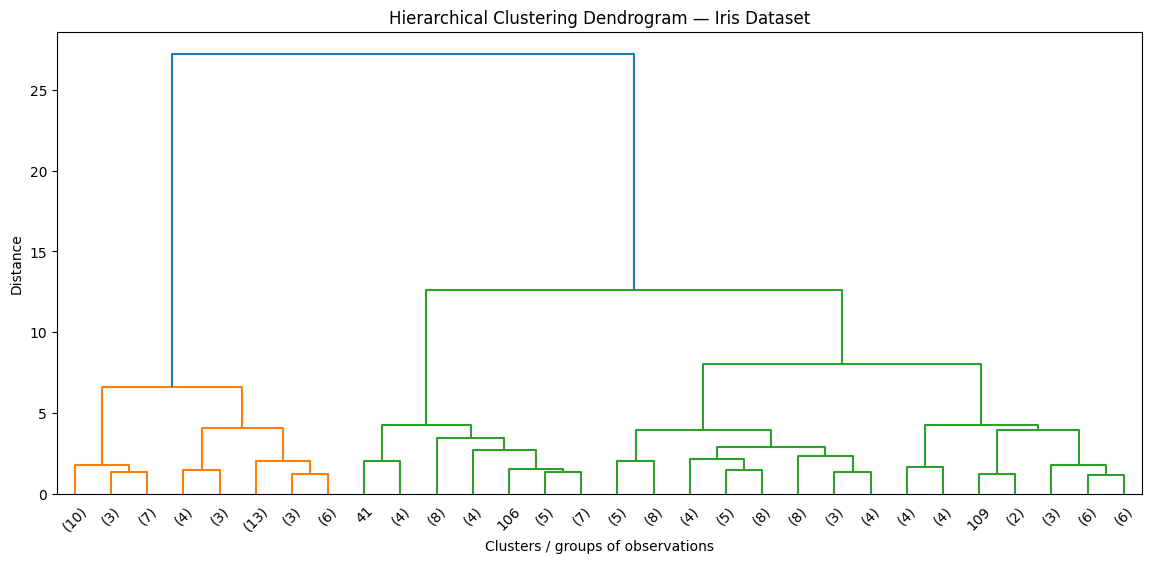

In [ ]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.xlabel("Clusters / groups of observations")
plt.ylabel("Distance")
plt.title("Hierarchical Clustering Dendrogram — Iris Dataset")
plt.show()


## 4. How do we decide the number of clusters?

Imagine drawing a **horizontal line** across the dendrogram.

Count how many vertical branches the line crosses.

**Number of branches crossed = number of clusters.**

For this demonstration, we choose a cut that gives **3 clusters**.

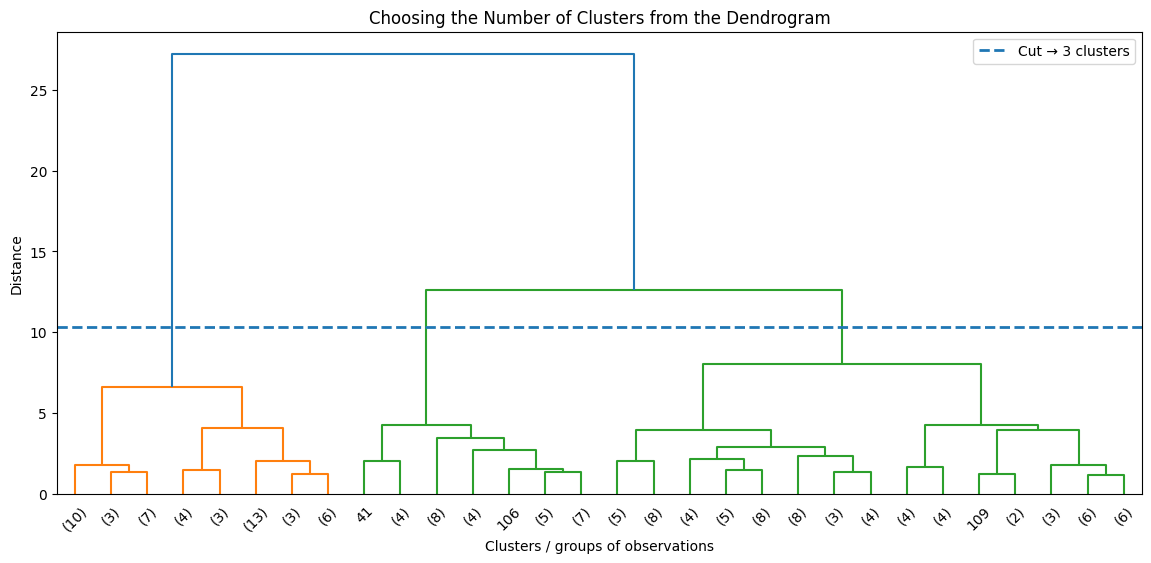

In [ ]:
# A cut chosen between the merge distances that produce
# 3 clusters and 2 clusters
cut_height =(Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.axhline(
    y=cut_height,
    linestyle="--",
    linewidth=2,
    label="Cut → 3 clusters"
)

plt.xlabel("Clusters / groups of observations")
plt.ylabel("Distance")
plt.title("Choosing the Number of Clusters from the Dendrogram")
plt.legend()
plt.show()


## 5. Apply Agglomerative Clustering

Now we use the number suggested by our dendrogram:

**n_clusters = 3**

In [ ]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

labels = model.fit_predict(X_scaled)

print("Cluster labels:")
print(labels)


Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


## 6. Visualize the final clusters

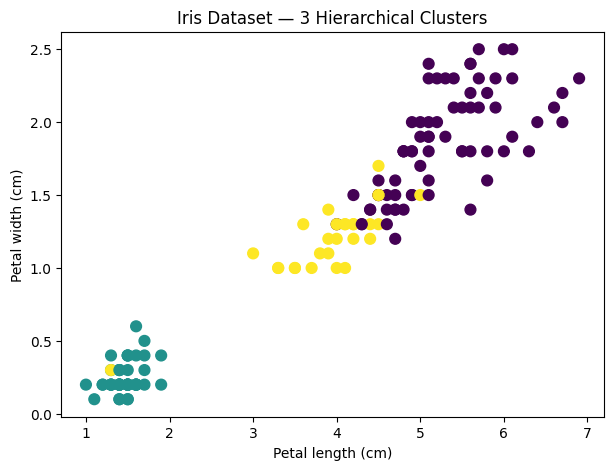

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 2],
    X[:, 3],
    c=labels,
    s=60
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Iris Dataset — 3 Hierarchical Clusters")
plt.show()


# Final takeaway

**Real dataset → Dendrogram → Horizontal cut → Count branches → Choose number of clusters → Agglomerative Clustering**

In this example:

**Dendrogram cut → 3 clusters → AgglomerativeClustering(n_clusters=3)**

The original species labels were not used to create the clusters.